# A deterministic model: the birth-death example as an ODE

This notebook runs nested sampling on a **deterministic** model. The differential equation is integrated inside Rust with a stiff solver, the likelihood is exact, and LF-NS reduces to parallel nested sampling with its DP-GMM proposal and its termination criterion.

The model and data are those of `birth_death_petab.ipynb`, now read as the ordinary differential equation

$$\frac{d\,\mathrm{mRNA}}{dt} = k - \gamma\,\mathrm{mRNA}, \qquad \mathrm{mRNA}(0) = 0 .$$

A deterministic model cannot produce the fluctuations of a single cell. The standard deviation of the read-out is therefore estimated as a third parameter `sigma`, which absorbs those fluctuations together with the measurement noise. All three parameters, `k`, `gamma_mRNA`, and `sigma`, have log-uniform priors.

1. The problem files
2. Simulating the ODE
3. The likelihood
4. The nested sampling run
5. The posterior against the exact posterior
6. Posterior predictive check

The ODE has the closed-form solution `mRNA(t) = k/gamma (1 - exp(-gamma t))`, so the exact evidence and posterior can be computed on a grid for comparison.

To run: `uv sync` in the repository root, then `uv run jupyter lab`.

In [1]:
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

import lfns
import notebook_style as style

style.apply()
EXAMPLE = Path("..") / "examples" / "birth_death_ode"

## 1. The problem files

The SBML model, the measurements, and the condition table are shared with the stochastic example. Only two tables differ:

- `parameters.tsv` now estimates three parameters;
- `observables.tsv` uses the parameter `sigma` as the noise formula. `sigma` is not part of the SBML model; it exists only in the PEtab tables.

In [2]:
for name in ["problem.yaml", "parameters.tsv", "observables.tsv"]:
    print(f"--- {name}\n{(EXAMPLE / name).read_text()}")

--- problem.yaml
format_version: 1
parameter_file: parameters.tsv
problems:
  - sbml_files:
      - ../birth_death/birth_death.xml
    measurement_files:
      - ../birth_death/measurements.tsv
    condition_files:
      - ../birth_death/conditions.tsv
    observable_files:
      - observables.tsv

--- parameters.tsv
parameterId	parameterName	parameterScale	lowerBound	upperBound	nominalValue	estimate
k	transcription rate	log10	0.1	10	1	1
gamma_mRNA	degradation rate	log10	0.01	1	0.1	1
sigma	standard deviation of the read-out	log10	0.5	20	3	1

--- observables.tsv
observableId	observableName	observableFormula	noiseFormula	noiseDistribution
mRNA_read	mRNA count read-out	mRNA	sigma	normal



## 2. Simulating the ODE

`dynamics="deterministic"` selects the ODE. The rate laws of the SBML model are the terms of the right-hand side, and their symbolic derivatives give the Jacobian for the implicit (BDF) solver.

estimated parameters: ['k', 'gamma_mRNA', 'sigma']
largest deviation of the solver from the closed-form solution: 1.9e-07


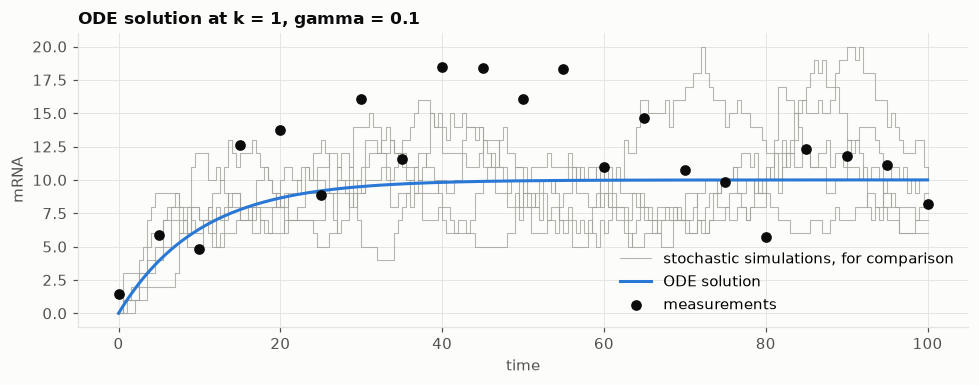

In [3]:
problem = lfns.PetabProblem(str(EXAMPLE / "problem.yaml"))
PARAMETER_IDS = problem.parameter_ids
print("estimated parameters:", PARAMETER_IDS)

data_times, _, data_values = problem.measurements()[0]
fine_times = np.linspace(0.0, 100.0, 201)
nominal = np.array([1.0, 0.1, 3.0])  # k, gamma_mRNA, sigma

solution, _ = problem.simulate(nominal, fine_times, dynamics="deterministic")
closed_form = nominal[0] / nominal[1] * (1.0 - np.exp(-nominal[1] * fine_times))
print(f"largest deviation of the solver from the closed-form solution: {np.abs(solution[:, 0] - closed_form).max():.1e}")

fig, ax = plt.subplots(figsize=(9, 3.6))
for seed in range(5):
    stochastic, _ = problem.simulate(nominal, fine_times, seed, dynamics="stochastic")
    ax.step(fine_times, stochastic[:, 0], where="post", color=style.NEUTRAL, lw=0.7, alpha=0.8,
            label="stochastic simulations, for comparison" if seed == 0 else None)
ax.plot(fine_times, solution[:, 0], color=style.BLUE, label="ODE solution")
ax.scatter(data_times, data_values, s=36, color=style.INK, zorder=3, label="measurements")
ax.set_xlabel("time"); ax.set_ylabel("mRNA"); ax.set_title("ODE solution at k = 1, gamma = 0.1"); ax.legend(loc="lower right")
fig.tight_layout()

The ODE follows the mean of the stochastic model. The measurements scatter around it by more than the measurement noise of 2, which is what `sigma` has to account for.

## 3. The likelihood

For a deterministic model the likelihood is a number, not an estimate: evaluating it twice gives the same value, and no particle filter is involved.

In [4]:
def exact_log_likelihood(k, gamma, sigma):
    # Closed-form solution of the ODE and normal noise; broadcasts over arrays of parameters.
    k, gamma, sigma = (np.asarray(value, dtype=float)[..., None] for value in (k, gamma, sigma))
    mean = k / gamma * (1.0 - np.exp(-gamma * data_times))
    return np.sum(-0.5 * ((data_values - mean) / sigma) ** 2 - np.log(sigma) - 0.5 * np.log(2.0 * np.pi), axis=-1)

from_rust = problem.log_likelihood(nominal, dynamics="deterministic")
print(f"log-likelihood from the Rust ODE solver: {from_rust:.6f}")
print(f"log-likelihood from the closed form:     {float(exact_log_likelihood(*nominal)):.6f}")

n_evaluations = 5000
start = time.perf_counter()
for _ in range(n_evaluations):
    problem.log_likelihood(nominal, dynamics="deterministic")
print(f"one likelihood evaluation: {1e6 * (time.perf_counter() - start) / n_evaluations:.0f} microseconds (including the call from Python)")

log-likelihood from the Rust ODE solver: -65.284431
log-likelihood from the closed form:     -65.284430


one likelihood evaluation: 405 microseconds (including the call from Python)


## 4. The nested sampling run

400 live points, 40 replaced per iteration, the default termination tolerance of 0.01. The replacements of an iteration are evaluated in parallel, and the result is a function of the seed.

In [5]:
SETTINGS = dict(n_live=400, n_replaced=40, seed=0, dynamics="deterministic")

start = time.perf_counter()
result = problem.run(**SETTINGS)
elapsed = time.perf_counter() - start
reports = result.reports()

# Exact evidence: the average of the exact likelihood over the unit cube, on a midpoint grid.
GRID_SIZE = 160
unit_axis = (np.arange(GRID_SIZE) + 0.5) / GRID_SIZE
axes_values = [problem.to_parameters(np.column_stack([unit_axis if d == i else np.full(GRID_SIZE, 0.5) for d in range(3)]))[:, i]
               for i in range(3)]
grid_log_likelihood = exact_log_likelihood(axes_values[0][:, None, None], axes_values[1][None, :, None], axes_values[2][None, None, :])
shift = grid_log_likelihood.max()
EXACT_LOG_EVIDENCE = shift + np.log(np.mean(np.exp(grid_log_likelihood - shift)))

print(f"stopped because:        {result.stop_reason}")
print(f"iterations:             {result.n_iterations}")
print(f"likelihood evaluations: {result.n_proposals}")
print(f"failed ODE solves:      {int(reports['n_failures'].sum())}")
print(f"ln Z:                   {result.log_evidence:.3f} +- {result.relative_std:.3f}")
print(f"exact ln Z (grid):      {EXACT_LOG_EVIDENCE:.3f}")
print(f"wall time:              {elapsed:.1f} s")

stopped because:        converged
iterations:             50
likelihood evaluations: 6223
failed ODE solves:      0
ln Z:                   -62.906 +- 0.123
exact ln Z (grid):      -62.922
wall time:              24.5 s


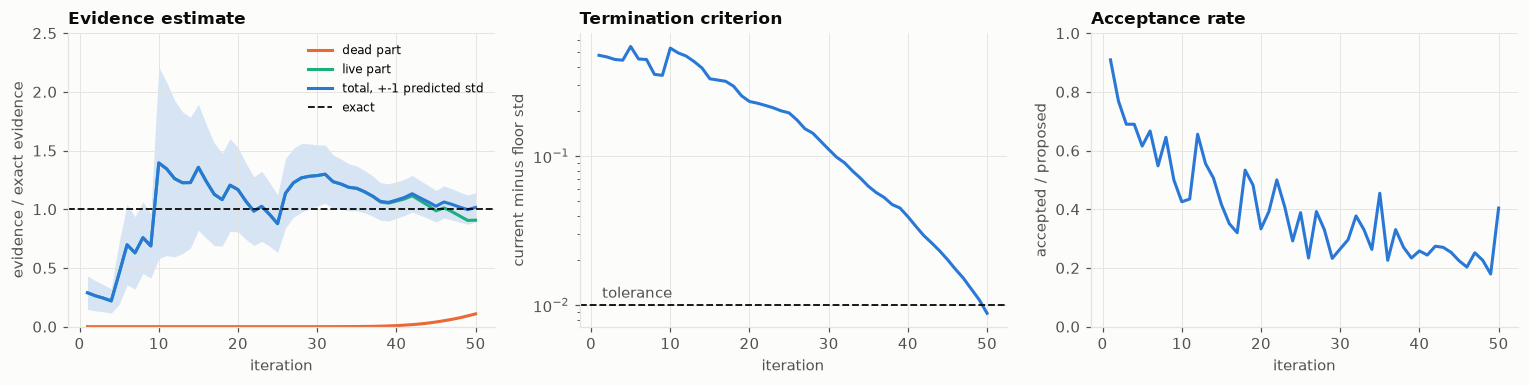

In [6]:
TOTAL, DEAD, LIVE = style.BLUE, style.ORANGE, style.AQUA
iteration = reports["iteration"]
scale = np.exp(-EXACT_LOG_EVIDENCE)
total = np.exp(reports["log_evidence"]) * scale
band = total * reports["relative_std"]

fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
ax_z, ax_gap, ax_rate = axes
ax_z.fill_between(iteration, total - band, total + band, color=TOTAL, alpha=0.18, linewidth=0)
ax_z.plot(iteration, np.exp(reports["log_dead_evidence"]) * scale, color=DEAD, label="dead part")
ax_z.plot(iteration, np.exp(reports["log_live_evidence"]) * scale, color=LIVE, label="live part")
ax_z.plot(iteration, total, color=TOTAL, label="total, +-1 predicted std")
ax_z.axhline(1.0, color=style.INK, lw=1.2, ls="--", label="exact")
ax_z.set_ylim(0.0, 2.5); ax_z.set_xlabel("iteration"); ax_z.set_ylabel("evidence / exact evidence")
ax_z.set_title("Evidence estimate"); ax_z.legend(fontsize=8)

ax_gap.plot(iteration, reports["achievable_improvement"], color=TOTAL)
ax_gap.axhline(0.01, color=style.INK, lw=1.2, ls="--")
ax_gap.annotate("tolerance", (iteration[0], 0.01), textcoords="offset points", xytext=(2, 5), color=style.MUTED)
ax_gap.set_yscale("log"); ax_gap.set_xlabel("iteration"); ax_gap.set_ylabel("current minus floor std")
ax_gap.set_title("Termination criterion")

ax_rate.plot(iteration, reports["acceptance_rate"], color=TOTAL)
ax_rate.set_ylim(0.0, 1.0); ax_rate.set_xlabel("iteration"); ax_rate.set_ylabel("accepted / proposed")
ax_rate.set_title("Acceptance rate")
fig.tight_layout()

Two things to notice.

- **The early error band is too narrow.** In the first few iterations the estimate sits near 0.3 of the exact evidence while the band excludes 1. The predicted error is computed from the spread of the live likelihoods, and before any live point has found the region of high likelihood that spread says nothing about what is still missing. The band becomes trustworthy once the estimate has stabilised, which is also when the termination criterion starts to fall.
- **The acceptance rate falls, but for a different reason than with a noisy likelihood.** A proposal is rejected only when it lies outside the region where the likelihood exceeds the threshold, so the rate measures how tightly the DP-GMM proposal region wraps that region. Here the region is a thin, curved ridge (see below), which is hard to wrap tightly, and the rate drops from near 1 to between 0.2 and 0.4.

## 5. The posterior

Weighted posterior points from the run against the exact marginal posteriors from the grid. The lower row shows the pairwise structure: `k` and `gamma_mRNA` are strongly correlated, because the data mostly determine the steady state `k / gamma`.

2400 weighted points, effective sample size 244



parameter     LF-NS mean  exact mean  LF-NS std  exact std
k                 2.1575      2.1729     1.4596     1.5305
gamma_mRNA        0.1741      0.1750     0.1255     0.1306
sigma             3.8399      3.8253     0.6627     0.6601


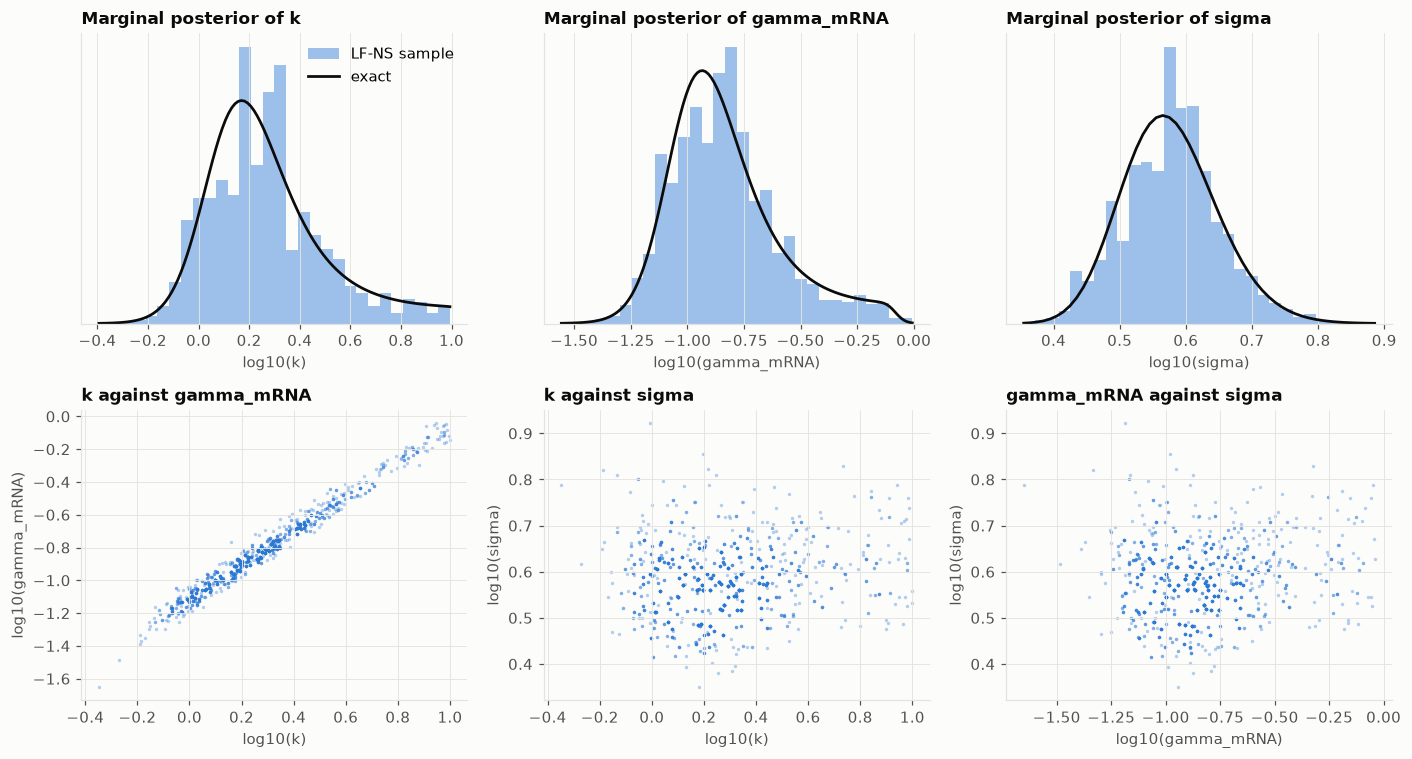

In [7]:
unit_points, log_weights = result.posterior()
samples = problem.to_parameters(unit_points)
weights = np.exp(log_weights)
print(f"{len(samples)} weighted points, effective sample size {result.effective_sample_size():.0f}")

grid_posterior = np.exp(grid_log_likelihood - shift)
grid_posterior /= grid_posterior.sum()
print(f"\n{'parameter':12} {'LF-NS mean':>11} {'exact mean':>11} {'LF-NS std':>10} {'exact std':>10}")
for index, name in enumerate(PARAMETER_IDS):
    marginal = grid_posterior.sum(axis=tuple(d for d in range(3) if d != index))
    exact_mean = np.sum(marginal * axes_values[index])
    exact_std = np.sqrt(np.sum(marginal * (axes_values[index] - exact_mean) ** 2))
    mean = np.sum(weights * samples[:, index])
    std = np.sqrt(np.sum(weights * (samples[:, index] - mean) ** 2))
    print(f"{name:12} {mean:>11.4f} {exact_mean:>11.4f} {std:>10.4f} {exact_std:>10.4f}")

fig, axes = plt.subplots(2, 3, figsize=(13, 7))
for index, (name, ax) in enumerate(zip(PARAMETER_IDS, axes[0])):
    log_values = np.log10(samples[:, index])
    log_axis = np.log10(axes_values[index])
    marginal = grid_posterior.sum(axis=tuple(d for d in range(3) if d != index))
    density = marginal / (log_axis[1] - log_axis[0])  # density per unit of log10(parameter)
    visible = density > 1e-3 * density.max()
    span = (log_axis[visible].min(), log_axis[visible].max())
    ax.hist(log_values, bins=30, range=span, weights=weights, density=True, color=style.BLUE, alpha=0.45, label="LF-NS sample")
    ax.plot(log_axis[visible], density[visible], color=style.INK, lw=1.8, label="exact")
    ax.set_xlabel(f"log10({name})"); ax.set_yticks([]); ax.set_title(f"Marginal posterior of {name}")
axes[0, 0].legend()

rng = np.random.default_rng(0)
drawn = rng.choice(len(samples), size=1500, p=weights / weights.sum())
for (i, j), ax in zip([(0, 1), (0, 2), (1, 2)], axes[1]):
    ax.scatter(np.log10(samples[drawn, i]), np.log10(samples[drawn, j]), s=5, color=style.BLUE, alpha=0.35, linewidths=0)
    ax.set_xlabel(f"log10({PARAMETER_IDS[i]})"); ax.set_ylabel(f"log10({PARAMETER_IDS[j]})")
    ax.set_title(f"{PARAMETER_IDS[i]} against {PARAMETER_IDS[j]}")
fig.tight_layout()

## 6. Posterior predictive check

ODE solutions for parameter values drawn from the posterior, and the band in which 95% of noisy measurements are expected.

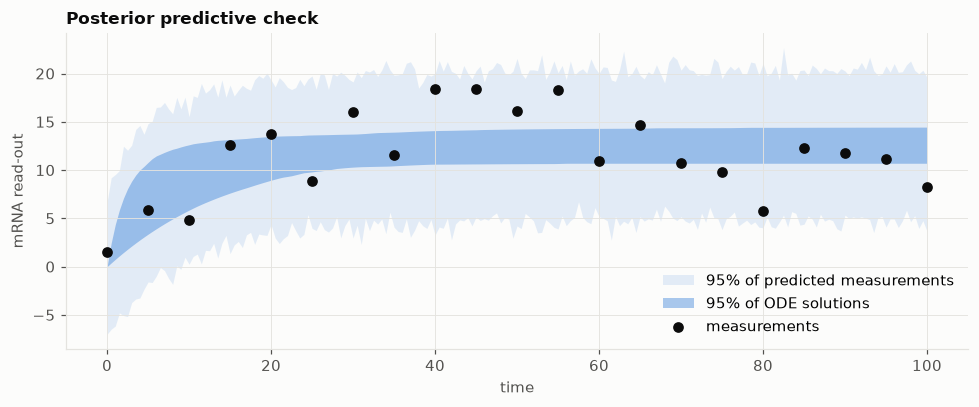

In [8]:
rng = np.random.default_rng(1)
predicted_curves, predicted_measurements = [], []
for index in rng.choice(len(samples), size=300, p=weights / weights.sum()):
    species, _ = problem.simulate(samples[index], fine_times, dynamics="deterministic")
    predicted_curves.append(species[:, 0])
    predicted_measurements.append(species[:, 0] + samples[index, 2] * rng.standard_normal(len(fine_times)))
curve_low, curve_high = np.percentile(predicted_curves, [2.5, 97.5], axis=0)
measured_low, measured_high = np.percentile(predicted_measurements, [2.5, 97.5], axis=0)

fig, ax = plt.subplots(figsize=(9, 3.8))
ax.fill_between(fine_times, measured_low, measured_high, color=style.BLUE, alpha=0.12, linewidth=0, label="95% of predicted measurements")
ax.fill_between(fine_times, curve_low, curve_high, color=style.BLUE, alpha=0.4, linewidth=0, label="95% of ODE solutions")
ax.scatter(data_times, data_values, s=36, color=style.INK, zorder=3, label="measurements")
ax.set_xlabel("time"); ax.set_ylabel("mRNA read-out"); ax.set_title("Posterior predictive check"); ax.legend(loc="lower right")
fig.tight_layout()

## Notes

- The stochastic and the deterministic example share one SBML file. Which dynamics are used is a choice made when running, not a property of the model file. For reactions of higher order the two readings of a rate law differ (a propensity counts pairs of molecules), so a model should be written for the dynamics it is meant for.
- A failed ODE solve is counted as zero likelihood and reported per iteration (`n_failures`); here there were none.
- The supported subset of SBML and PEtab is the same as for the stochastic example.